# 02 · Preparação, modelagem e interpretação

> ⚠️ **Dados 100% simulados.** A base foi gerada por `src/generate_data.py` (seed=42) apenas para fins de portfólio.

**Pergunta:** dá para prever, no momento do cadastro, quais leads vão comprar?

Este notebook tem três partes:
1. **Preparação dos dados:** tratamento, features e divisão sem vazamento (código em `src/features.py`).
2. **Modelagem:** regressão logística como baseline e XGBoost como modelo principal (código em `src/train.py`).
3. **Interpretação:** o que o modelo aprendeu, explicado com SHAP.

## Parte 1 · Preparação dos dados

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.features import (
    EXCLUDED_COLUMNS, NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES,
    add_features, build_preprocessor, load_leads, split_data,
)
from src.plots import COLORS, conversion_by, plot_rate_bars, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
df = load_leads()

### 1.1 Divisão treino / validação / teste (70/15/15)

A divisão é feita **antes de qualquer tratamento** e é **estratificada pelo alvo**. Com só 4% de compradores, uma divisão
aleatória simples poderia deixar o teste com uma taxa de conversão diferente, distorcendo as métricas.

- **Treino (70%):** ajusta o pré-processamento e os modelos, e é onde roda a validação cruzada.
- **Validação (15%):** compara modelos e escolhe o limiar de decisão.
- **Teste (15%):** fica guardado até o fim e é usado uma única vez, para a estimativa final e a análise de impacto.

In [2]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)

pd.DataFrame({
    "leads": [len(y_train), len(y_val), len(y_test)],
    "conversoes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "taxa_conversao": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["treino", "validacao", "teste"])

,leads,conversoes,taxa_conversao
treino,35000,1411,0.040
validacao,7500,303,0.040
teste,7500,302,0.040


**Conclusão:** os três conjuntos têm a mesma taxa de conversão (4,03–4,04%), como esperado com a estratificação.
São cerca de 300 compradores na validação e no teste, o suficiente para comparar modelos com estabilidade razoável.

### 1.2 Tratamento de ausentes e outliers

| Problema | Tratamento | Justificativa |
|---|---|---|
| ~2% de ausentes em `idade` e `tempo_no_site_seg` | Mediana **do treino** | A mediana é robusta à cauda longa do tempo no site, e calcular só no treino evita vazamento. |
| ~2% de ausentes em `dispositivo` e `uf` | Categoria `"desconhecido"` | Falha de rastreamento pode ter padrão próprio, e a categoria extra preserva essa informação. |
| Sessões acima de 1 hora (0,5%) | Capping em 3.600 s | Abas esquecidas e bots. Limitar o valor em vez de remover a linha mantém o lead, e o teto é uma regra de negócio fixa, que não depende dos dados. |
| UFs com menos de 1% dos leads | Agrupadas em "infrequente" | Evita colunas com pouquíssimos exemplos, que só adicionam ruído. |

### 1.3 Features novas

| Feature | Como é calculada | Por que (achado da EDA) |
|---|---|---|
| `faixa_etaria` | 18–24, 25–34, 35–44, 45–60 | A conversão cresce com a idade. |
| `periodo_do_dia` | madrugada (0–5h), manhã (6–11h), tarde (12–17h), noite (18–23h) | O horário muda a intenção de compra. |
| `dia_da_semana` | segunda a domingo | Captura sazonalidade semanal sem decorar datas. |
| `engajamento` | log(1 + páginas) + log(1 + minutos no site) | Combina duas medidas de interesse na mesma escala. |
| `mobile_noite` | celular **e** cadastro entre 22h e 6h | Foi o segmento com a pior conversão na EDA. A regressão logística não cria essa interação sozinha. |

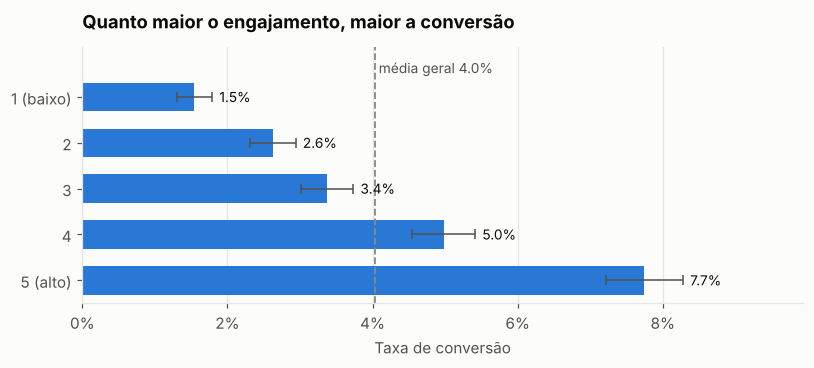

,leads,conversoes,taxa,ic95
quintil_engajamento,,,,
1 (baixo),9840,152,0.015,0.002
2,9799,257,0.026,0.003
3,9805,331,0.034,0.004
4,9778,487,0.050,0.004
5 (alto),9797,759,0.077,0.005


In [3]:
com_features = add_features(df)
com_features["quintil_engajamento"] = pd.qcut(
    com_features["engajamento"], 5, labels=["1 (baixo)", "2", "3", "4", "5 (alto)"]
)
por_engajamento = conversion_by(com_features, "quintil_engajamento")
fig = plot_rate_bars(
    por_engajamento, "Quanto maior o engajamento, maior a conversão",
    com_features["converteu"].mean(), sort=False, show_ci=True,
)
save_figure(fig, "10_conversao_por_engajamento")
plt.show()
por_engajamento

**Conclusão:** a nova feature `engajamento` separa bem os leads: os 20% mais engajados convertem **5 vezes mais** (7,8%) que os 20% menos
engajados (1,5%), com crescimento consistente entre os quintis. É um sinal forte, construído só com dados disponíveis no cadastro.

### 1.4 A coluna `custo_aquisicao_lead` deve entrar no modelo?

Há argumentos para os dois lados:

- **A favor:** o custo pode indicar um lead "disputado" no leilão de mídia, que talvez tenha mais intenção.
- **Contra:** (1) ele é quase todo explicado pelo canal, que já está no modelo; (2) na prática, o custo por lead é **rateado depois**,
  quando a fatura da campanha fecha, então não estaria disponível no momento de pontuar um lead novo, e usá-lo seria um tipo de vazamento temporal;
  (3) o custo é o que queremos **otimizar** na análise de impacto, e usá-lo como entrada misturaria causa e consequência.

Vamos verificar o argumento (1) com os dados:

In [4]:
from sklearn.linear_model import LinearRegression

canais = pd.get_dummies(df["canal"])
r2_canal = LinearRegression().fit(canais, df["custo_aquisicao_lead"]).score(canais, df["custo_aquisicao_lead"])
print(f"R² do custo explicado apenas pelo canal: {r2_canal:.1%}")

df.groupby("canal")["custo_aquisicao_lead"].describe()[["mean", "std", "min", "max"]]

R² do custo explicado apenas pelo canal: 65.7%


,mean,std,min,max
canal,,,,
email,2.663,0.954,0.670,8.360
google_ads,19.207,6.957,5.050,70.450
meta_ads,12.702,4.554,2.950,54.290
organico,1.064,0.381,0.230,3.820
tiktok_ads,9.542,3.445,2.260,29.060


**Conclusão:** só o canal já explica cerca de **2/3 da variação do custo** (R² de 66%), e o resto é variação aleatória em torno do custo médio do canal.
**Decisão: o custo fica fora do modelo.** Ele traria pouca informação nova, não estaria disponível em tempo real e será usado, separadamente,
para medir o impacto em CPA na Etapa 6. Também ficam de fora `lead_id` (identificador), `data_cadastro` e `horario_cadastro`
(substituídas por `dia_da_semana` e `periodo_do_dia`).

### 1.5 Pipeline sem vazamento de dados

Todo o pré-processamento fica em um único `Pipeline` do scikit-learn:

```
Pipeline
├── features: add_features (capping + features novas, linha a linha)
└── columns: ColumnTransformer
    ├── num: SimpleImputer(mediana) → StandardScaler
    ├── bin: passthrough
    └── cat: SimpleImputer("desconhecido") → OneHotEncoder
```

O pipeline é ajustado (`fit`) **só no treino**. Na validação cruzada, ele é reajustado dentro de cada fold, então nem o fold
de validação "vaza" as medianas, médias ou categorias para o treino.

In [5]:
preprocessador = build_preprocessor()
X_train_proc = preprocessador.fit_transform(X_train)
X_test_proc = preprocessador.transform(X_test)
nomes = preprocessador.named_steps["columns"].get_feature_names_out()

mediana_treino = preprocessador.named_steps["columns"].named_transformers_["num"].named_steps["imputer"].statistics_
print(f"Treino: {X_train_proc.shape} | Teste: {X_test_proc.shape}")
print(f"Ausentes depois do pipeline: {np.isnan(X_train_proc).sum() + np.isnan(X_test_proc).sum()}")
print("Medianas aprendidas SÓ no treino:", {c: round(float(v), 2) for c, v in zip(NUMERIC_FEATURES, mediana_treino)})
print(f"Colunas excluídas: {EXCLUDED_COLUMNS}")
print(f"{len(nomes)} colunas finais, por exemplo: {list(nomes[:10])}")

Treino: (35000, 61) | Teste: (7500, 61)
Ausentes depois do pipeline: 0
Medianas aprendidas SÓ no treino: {'idade': 32.0, 'paginas_vistas': 4.0, 'tempo_no_site_seg': 104.0, 'engajamento': 2.62}
Colunas excluídas: ['lead_id', 'data_cadastro', 'horario_cadastro', 'custo_aquisicao_lead']
61 colunas finais, por exemplo: ['idade', 'paginas_vistas', 'tempo_no_site_seg', 'engajamento', 'visitou_pagina_preco', 'abriu_email', 'mobile_noite', 'canal_email', 'canal_google_ads', 'canal_meta_ads']


**Conclusão:** o pipeline gera 61 colunas sem nenhum valor ausente, e as estatísticas de imputação vêm só do treino.
O mesmo objeto será acoplado aos modelos na Parte 2, então quem usar o modelo em produção passa os dados brutos e recebe a probabilidade:
o tratamento vai junto.

## Parte 2 · Modelagem

### 2.1 Por que acurácia não serve aqui

Com 4% de compradores, um "modelo" que responde **"ninguém compra"** para todo mundo já acerta 96% das vezes.
A conta abaixo mostra isso na validação:

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, average_precision_score

ingenuo = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Acurácia do modelo 'ninguém compra': {accuracy_score(y_val, ingenuo.predict(X_val)):.1%}")
print(f"Compradores que ele encontra: {ingenuo.predict(X_val).sum()} de {y_val.sum()}")
print(f"PR-AUC de um ranking aleatório (= taxa de conversão): {y_val.mean():.3f}")

Acurácia do modelo 'ninguém compra': 96.0%
Compradores que ele encontra: 0 de 303
PR-AUC de um ranking aleatório (= taxa de conversão): 0.040


**Conclusão:** 96% de acurácia e zero compradores encontrados. A acurácia premia acertar a classe majoritária, que não interessa.
Por isso usamos:

- **PR-AUC (métrica principal):** resume precision × recall em todos os limiares. A referência de um ranking aleatório é a própria taxa de conversão (0,04), então qualquer valor acima disso é ganho real.
- **ROC-AUC:** a probabilidade de um comprador receber score maior que um não comprador. É útil, mas fica otimista em bases desbalanceadas.
- **Precision e recall nos 30% melhores leads:** a tradução direta para a operação ("dos leads que priorizamos, quantos compram?" e "que fatia das vendas capturamos?").
- **Curva de calibração e Brier score:** a probabilidade prevista bate com a frequência real? Isso importa para projetar vendas e receita.

### 2.2 Treino dos modelos

O treino está em `src/train.py` (rodado com `make train`). Aqui carregamos os modelos salvos e, se eles ainda não existirem, treinamos na hora.

- **Baseline:** regressão logística com `class_weight="balanced"`, que dá mais peso aos compradores raros.
- **Modelo principal:** XGBoost com `RandomizedSearchCV`, 15 combinações de hiperparâmetros × validação cruzada estratificada de 3 folds, otimizando a PR-AUC.

In [7]:
import json
import joblib
from src import train

if not train.MODEL_PATH.exists():
    train.main()

baseline = joblib.load(train.BASELINE_PATH)
modelo = joblib.load(train.MODEL_PATH)
metricas = json.loads(train.METRICS_PATH.read_text())
busca = pd.read_csv(train.CV_RESULTS_PATH)

print("Melhores hiperparâmetros:", metricas["melhores_hiperparametros"])
busca.head(5)

Melhores hiperparâmetros: {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,pr_auc_cv,pr_auc_cv_std
0,0.700,10,500,10,3,0.020,0.800,0.150,0.004
1,1.000,5,300,10,2,0.050,1.000,0.149,0.003
2,0.700,10,200,1,5,0.020,0.600,0.149,0.001
3,0.850,10,200,5,2,0.050,0.600,0.148,0.003
4,0.700,10,300,5,3,0.050,1.000,0.148,0.003


**Conclusão:** as 5 melhores combinações ficam todas entre 0,148 e 0,150 de PR-AUC na validação cruzada, com desvio de ~0,003 entre folds.
O modelo é pouco sensível aos hiperparâmetros. A melhor combinação usa **árvores rasas (profundidade 3), taxa de aprendizado baixa e
regularização forte**, ou seja, um modelo conservador, o que é um bom sinal contra overfitting.

### 2.3 Comparação na validação

In [8]:
NOMES = {"logistica": "Regressão logística", "xgboost": "XGBoost"}
comparacao = pd.DataFrame({NOMES[m]: metricas[m]["validacao"] for m in NOMES}).T
comparacao = comparacao[["pr_auc", "roc_auc", "precision", "recall", "brier"]]
comparacao.columns = ["PR-AUC", "ROC-AUC", "Precision (top 30%)", "Recall (top 30%)", "Brier"]
comparacao

,PR-AUC,ROC-AUC,Precision (top 30%),Recall (top 30%),Brier
Regressão logística,0.167,0.785,0.097,0.719,0.187
XGBoost,0.166,0.787,0.098,0.726,0.036


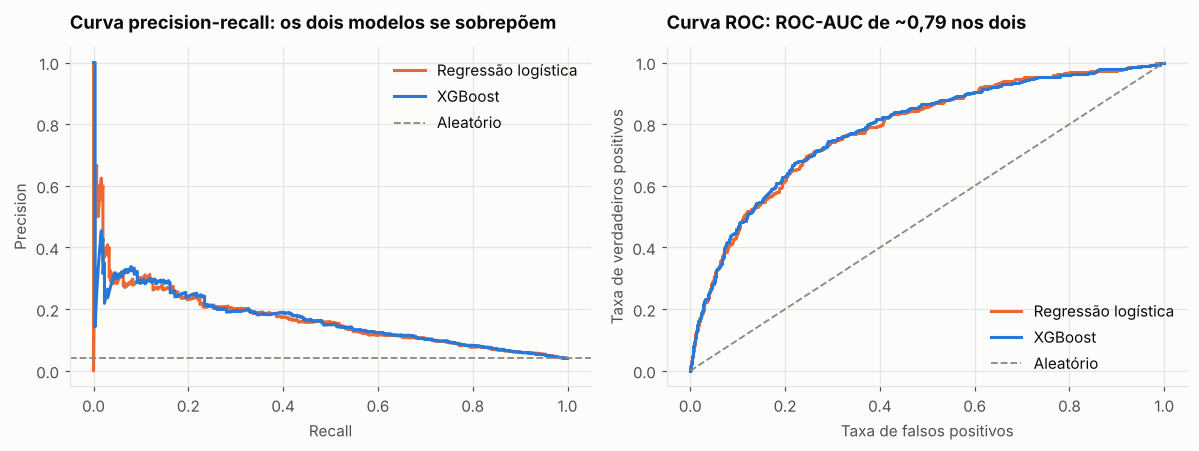

In [9]:
from sklearn.metrics import precision_recall_curve, roc_curve

scores_val = {
    NOMES["logistica"]: baseline.predict_proba(X_val)[:, 1],
    NOMES["xgboost"]: modelo.predict_proba(X_val)[:, 1],
}
cores = {NOMES["logistica"]: COLORS["secondary"], NOMES["xgboost"]: COLORS["primary"]}

fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(11, 4.2))
for nome, s in scores_val.items():
    precisao, recall, _ = precision_recall_curve(y_val, s)
    fpr, tpr, _ = roc_curve(y_val, s)
    ax_pr.plot(recall, precisao, color=cores[nome], linewidth=2, label=nome)
    ax_roc.plot(fpr, tpr, color=cores[nome], linewidth=2, label=nome)

ax_pr.axhline(y_val.mean(), color=COLORS["reference"], linestyle="--", linewidth=1.2, label="Aleatório")
ax_roc.plot([0, 1], [0, 1], color=COLORS["reference"], linestyle="--", linewidth=1.2, label="Aleatório")
ax_pr.set(title="Curva precision-recall: os dois modelos se sobrepõem", xlabel="Recall", ylabel="Precision")
ax_roc.set(title="Curva ROC: ROC-AUC de ~0,79 nos dois", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
for ax in (ax_pr, ax_roc):
    ax.legend(loc="upper right" if ax is ax_pr else "lower right")
fig.tight_layout()
save_figure(fig, "11_curvas_pr_roc")
plt.show()

**Conclusão:** os dois modelos são **4 vezes melhores que o acaso** em PR-AUC (0,17 contra 0,04) e têm ROC-AUC de 0,79. Priorizando os 30% de leads
com maior score, capturamos **~72% dos compradores**, com precision de ~9,7% (2,4 vezes a taxa média). Mas, em ranking, **o XGBoost empata com a
regressão logística**: as curvas praticamente se sobrepõem.

**Por que o modelo mais complexo não ganhou?** Os dados simulados foram gerados por uma função logística, em que cada variável soma
seu efeito de forma independente. Não há interações escondidas nem relações em forma de U para as árvores descobrirem, e a feature
`mobile_noite` já entrega à regressão logística a única interação relevante. É uma lição importante: **complexidade só se paga quando
o problema tem estrutura não linear**, e o baseline existe justamente para verificar isso.

### 2.4 Calibração: a probabilidade prevista é confiável?

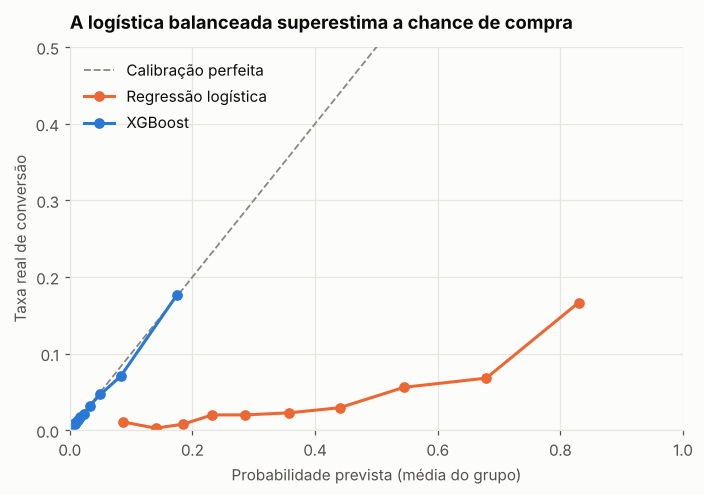

,Brier
Regressão logística,0.187
XGBoost,0.036


In [10]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot([0, 1], [0, 1], color=COLORS["reference"], linestyle="--", linewidth=1.2, label="Calibração perfeita")
for nome, s in scores_val.items():
    real, previsto = calibration_curve(y_val, s, n_bins=10, strategy="quantile")
    ax.plot(previsto, real, marker="o", markersize=6, color=cores[nome], linewidth=2, label=nome)
ax.set(title="A logística balanceada superestima a chance de compra",
       xlabel="Probabilidade prevista (média do grupo)", ylabel="Taxa real de conversão",
       xlim=(0, 1), ylim=(0, 0.5))
ax.legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "12_curva_calibracao")
plt.show()

comparacao[["Brier"]]

**Conclusão:** o XGBoost fica colado na diagonal: quando ele diz "10% de chance", cerca de 10% compram (Brier de 0,036).
A regressão logística com `class_weight="balanced"` **finge que a base tem 50% de compradores** e por isso superestima muito a chance de compra:
o grupo com 83% de probabilidade prevista compra só 17% (Brier de 0,187). O ranking dela continua bom, mas a probabilidade não pode ser usada para projetar vendas ou receita
sem uma recalibração (por exemplo, com `CalibratedClassifierCV`).

### 2.5 Escolha do modelo final e avaliação no teste

**Modelo final: XGBoost.** Ele empata no ranking (PR-AUC) e vence com folga na calibração, e probabilidades confiáveis são necessárias
para a análise de impacto em reais. Uma regressão logística sem balanceamento, ou recalibrada, também seria uma escolha defensável,
mais simples de explicar e de manter. Se este modelo fosse para produção, essa seria uma conversa a ter com o time.

O conjunto de **teste** é usado agora, pela primeira e única vez:

In [11]:
teste = pd.DataFrame({NOMES[m]: metricas[m]["teste"] for m in NOMES}).T
teste = teste[["pr_auc", "roc_auc", "precision", "recall", "brier"]]
teste.columns = ["PR-AUC", "ROC-AUC", "Precision (top 30%)", "Recall (top 30%)", "Brier"]
print(f"Modelo salvo em: {train.MODEL_PATH.relative_to(ROOT)}")
teste

Modelo salvo em: models/modelo_xgboost.joblib


,PR-AUC,ROC-AUC,Precision (top 30%),Recall (top 30%),Brier
Regressão logística,0.159,0.781,0.096,0.702,0.184
XGBoost,0.153,0.781,0.097,0.705,0.036


**Conclusão:** no teste, o XGBoost mantém o desempenho da validação (PR-AUC de 0,15, ROC-AUC de 0,78, recall de 70% nos 30% melhores leads),
então **não há sinal de overfitting**. O pipeline completo (pré-processamento + modelo) está salvo em `models/modelo_xgboost.joblib`:
basta passar os dados brutos de um lead novo para receber a probabilidade de compra.